<a href="https://colab.research.google.com/github/fajareka1/PCVK_Ganjil_2026_v2/blob/main/Modul_7_Praktikum___SEGMENTASI_CITRA_DENGAN_THRESHOLDING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


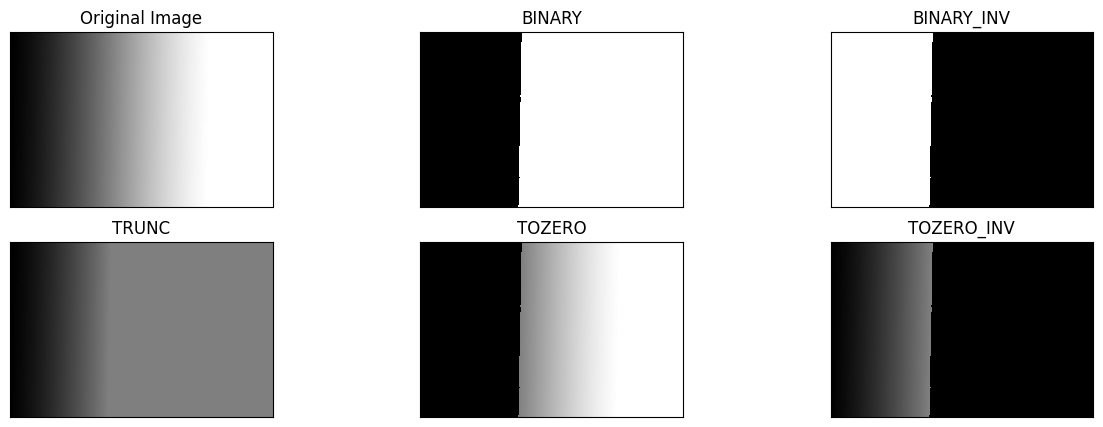

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

filename = ('/content/drive/MyDrive/PCVK/Images/gradient.jpg')
img = cv.imread(filename)
thresh = 127
maxvel = 255

#1. threshold binary jika pixel di img . 127
ret, thresh1 = cv.threshold(img, thresh, maxvel, cv.THRESH_BINARY)
#2. threshold binary inverse jika pixel > thresh
ret, thresh2 = cv.threshold(img, thresh, maxvel, cv.THRESH_BINARY_INV)
#3. threshold truncate jika pixel > thresh
ret, thresh3 = cv.threshold(img, thresh, maxvel, cv.THRESH_TRUNC)
#4. threshold Tozero jika pixel > thresh
ret, thresh4 = cv.threshold(img, thresh, maxvel, cv.THRESH_TOZERO)
#5. threshold Tozero inverse jika pixel > thresh
ret, thresh5 = cv.threshold(img, thresh, maxvel, cv.THRESH_TOZERO_INV)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
  plt.subplot(2, 3, i+1), plt.imshow(images[i], 'gray', interpolation = 'nearest')
  plt.title(titles[i])
  plt.xticks([]), plt.yticks([])
plt.show()

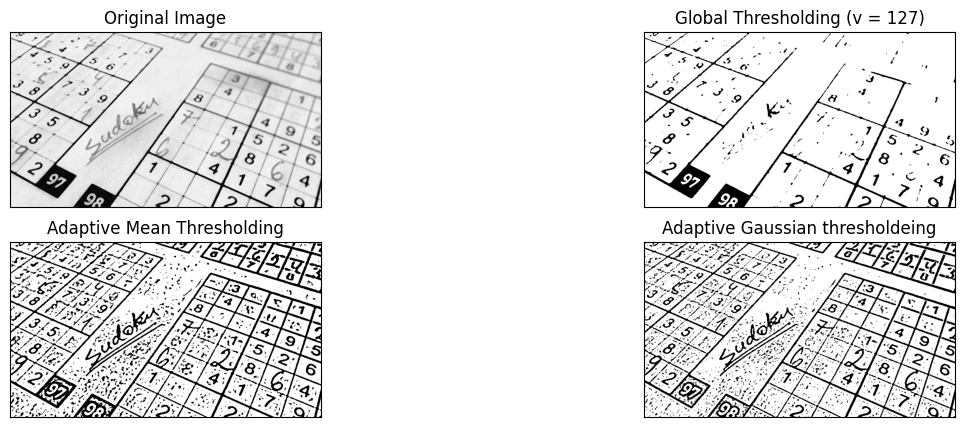

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images/sudoku.jpg')
citra = cv.medianBlur(cv.imread(filename), 5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127

ret, th1 = cv.threshold(gray, thresh, 255, cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2)
th3 = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

titles = ['Original Image', 'Global Thresholding (v = 127)', 'Adaptive Mean Thresholding', 'Adaptive Gaussian thresholdeing']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(15, 5))
for i in range(len(citra2)):
  plt.subplot(2, 2, i+1), plt.imshow(citra2[i], 'gray')
  plt.title(titles[i])
  plt.xticks([]), plt.yticks([])
plt.show()

/tmp/ipykernel_971/2135425970.py:14: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.subplot(2,2,1), plt.hist(blur.ravel(), 256, [50, 200])


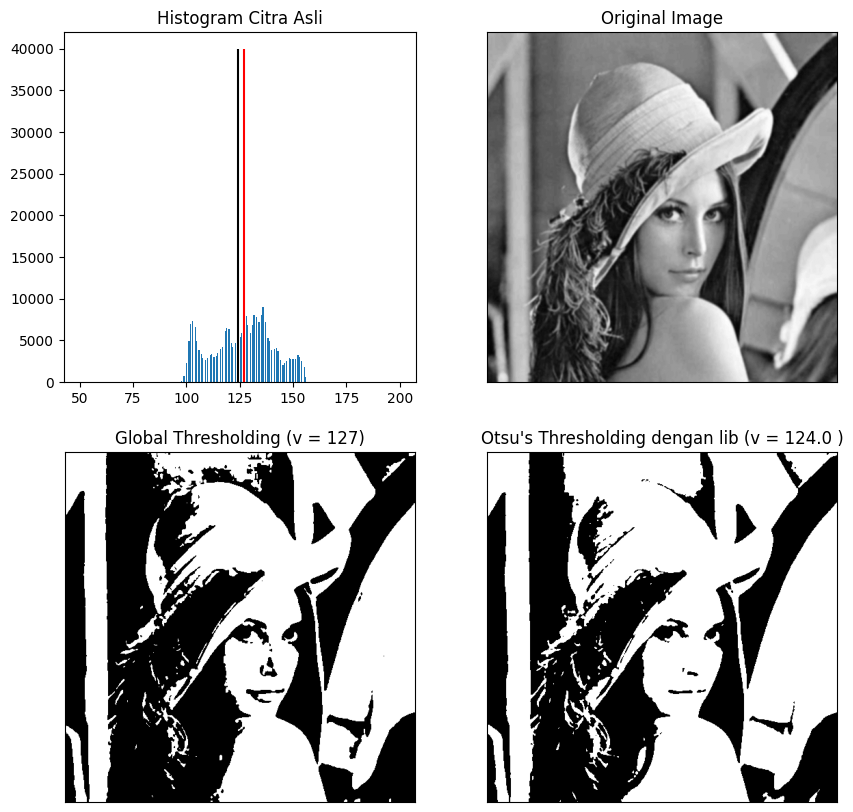

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images/lena_lc.jpeg')
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
ret2, th2 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

x = ("Otsu's Thresholding dengan lib (v = ") + str(ret2) +" )"
titles = ['Original Image', 'Global Thresholding (v = 127)', x]
citra3 = [blur, th1, th2]

plt.figure(figsize = (10, 10))
plt.subplot(2,2,1), plt.hist(blur.ravel(), 256, [50, 200])
plt.vlines(ret, 0, 40000, colors = 'red')

plt.vlines(ret2, 0, 40000, colors = 'black')

plt.title('Histogram Citra Asli')
for i in range(len(citra3)):
  plt.subplot(2, 2, i+2), plt.imshow(citra3[i], 'gray')
  plt.title(titles[i])
  plt.xticks([]), plt.yticks([])
plt.show()

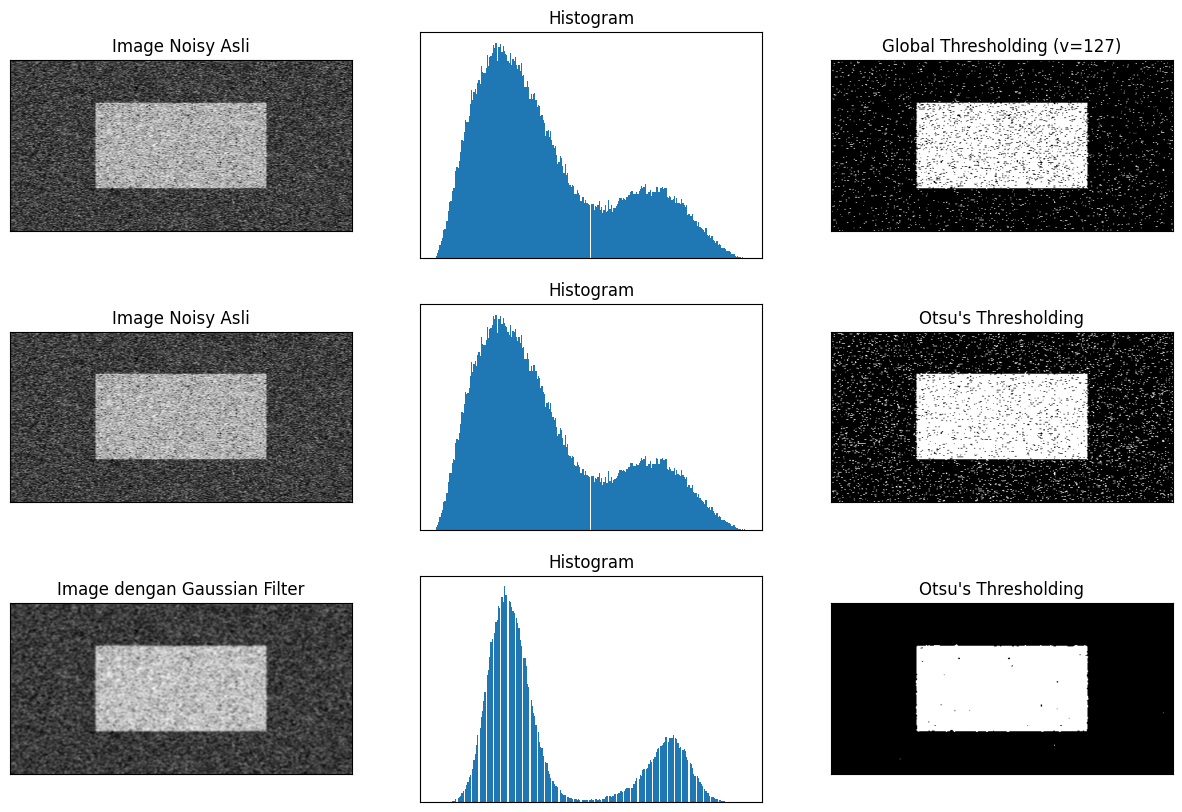

In [ ]:
filename = ('/content/drive/MyDrive/PCVK/Images2/noisy2.png')
img = cv.imread(filename,0)
#Global Thresholding
ret1,th1 = cv.threshold(img,127,255,cv.THRESH_BINARY)
# Otsu's thresholding
ret2,th2 = cv.threshold(img,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)
# Otsu's thresholding setelah dilakukan Gaussian filtering
blur = cv.GaussianBlur(img,(5,5),0)
ret3,th3 = cv.threshold(blur,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)
#plotting semua image
images = [img, 0, th1,
img, 0, th2,
blur, 0, th3]
titles = ['Image Noisy Asli','Histogram','Global Thresholding (v=127)',
'Image Noisy Asli','Histogram',"Otsu's Thresholding",
'Image dengan Gaussian Filter','Histogram',"Otsu's Thresholding"]
plt.figure(figsize = (15,10))
for i in range(3):
  plt.subplot(3,3,i*3+1),plt.imshow(images[i*3],'gray')
  plt.title(titles[i*3]), plt.xticks([]), plt.yticks([])
  plt.subplot(3,3,i*3+2),plt.hist(images[i*3].ravel(),256)
  plt.title(titles[i*3+1]), plt.xticks([]), plt.yticks([])
  plt.subplot(3,3,i*3+3),plt.imshow(images[i*3+2],'gray')
  plt.title(titles[i*3+2]), plt.xticks([]), plt.yticks([])
plt.show()

---
# TUGAS PRAKTIKUM — Lanjutan (Folder foto: `Images2`)
## D1. Tugas Individu
### No. 2 — Import library & lokasi folder gambar

In [ ]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from sklearn.cluster import KMeans
from IPython.display import display
import os

# Semua foto untuk tugas selanjutnya diambil dari folder Images2
BASE = '/content/drive/MyDrive/PCVK/Images2/'

def cari_file(*kandidat):
    """Cari file di folder Images2 (huruf besar/kecil tidak dibedakan)."""
    ada = os.listdir(BASE) if os.path.isdir(BASE) else []
    for k in kandidat:
        for f in ada:
            if f.lower() == k.lower():
                return BASE + f
    raise FileNotFoundError(f'{kandidat} tidak ditemukan di {BASE}\nIsi folder: {ada}')

print('Isi folder Images2:', sorted(os.listdir(BASE)) if os.path.isdir(BASE) else 'FOLDER TIDAK DITEMUKAN')

### No. 3 — Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV) secara manual, `thresh = 200`
Tanpa `cv.threshold()`: semua dihitung dengan NumPy (`np.where`) sesuai tabel ketentuan.

| Jenis | piksel > thresh | piksel ≤ thresh |
|---|---|---|
| BINARY | maxval | 0 |
| BINARY_INV | 0 | maxval |
| TRUNC | thresh | nilai asli |
| TOZERO | nilai asli | 0 |
| TOZERO_INV | 0 | nilai asli |

In [ ]:
img = cv.imread(cari_file('gradient.jpg'), 0)     # baca sebagai grayscale
thresh = 200
maxval = 255

def th_binary(src, t, mx=255):      return np.where(src > t, mx, 0).astype(np.uint8)
def th_binary_inv(src, t, mx=255):  return np.where(src > t, 0, mx).astype(np.uint8)
def th_trunc(src, t):               return np.where(src > t, t, src).astype(np.uint8)
def th_tozero(src, t):              return np.where(src > t, src, 0).astype(np.uint8)
def th_tozero_inv(src, t):          return np.where(src > t, 0, src).astype(np.uint8)

hasil_global = {
    'Original Image': img,
    'BINARY':         th_binary(img, thresh, maxval),
    'BINARY_INV':     th_binary_inv(img, thresh, maxval),
    'TRUNC':          th_trunc(img, thresh),
    'TOZERO':         th_tozero(img, thresh),
    'TOZERO_INV':     th_tozero_inv(img, thresh),
}

plt.figure(figsize=(15, 5))
for i, (judul, gbr) in enumerate(hasil_global.items()):
    plt.subplot(2, 3, i+1)
    plt.imshow(gbr, 'gray', vmin=0, vmax=255, interpolation='nearest')   # vmin/vmax agar TRUNC tidak ter-stretch
    plt.title(judul)
    plt.xticks([]), plt.yticks([])
plt.show()

# (Hanya verifikasi) bandingkan dengan hasil OpenCV
mode_cv = [cv.THRESH_BINARY, cv.THRESH_BINARY_INV, cv.THRESH_TRUNC, cv.THRESH_TOZERO, cv.THRESH_TOZERO_INV]
for (judul, gbr), m in zip(list(hasil_global.items())[1:], mode_cv):
    print(f'{judul:<11} sama dengan cv.threshold ->', np.array_equal(gbr, cv.threshold(img, thresh, maxval, m)[1]))

### No. 4 — Adaptive Threshold (Mean & Gaussian) manual pada citra Sudoku
Tanpa `cv.threshold()`, `cv.adaptiveThreshold()`, maupun fungsi filter siap pakai. Semua tahap ditulis dengan NumPy:

1. Grayscale: `0.299 R + 0.587 G + 0.114 B`
2. Median blur 5×5 (manual, seperti contoh modul)
3. Rata-rata lokal jendela 11×11 memakai **integral image** (summed-area table)
4. Rata-rata Gaussian lokal (kernel 11×11, σ = 2) memakai konvolusi separabel manual
5. Ambang lokal `T(x,y) = rata-rata − C` dengan `C = 2`; piksel `> T` menjadi putih (255), selain itu hitam (0)

In [ ]:
def ke_gray(bgr):
    b, g, r = [bgr[..., i].astype(np.float64) for i in range(3)]
    return np.round(0.299*r + 0.587*g + 0.114*b).astype(np.uint8)

def median_manual(gray, k=5):
    pad = k // 2
    p = np.pad(gray, pad, mode='reflect')
    jendela = np.lib.stride_tricks.sliding_window_view(p, (k, k))
    return np.median(jendela.reshape(gray.shape[0], gray.shape[1], -1), axis=2).astype(np.uint8)

def mean_lokal(gray, b):
    """Rata-rata jendela b x b di sekitar tiap piksel (integral image, tepi direplikasi)."""
    r = b // 2
    H, W = gray.shape
    p = np.pad(gray.astype(np.float64), r, mode='edge')
    ii = np.pad(p.cumsum(axis=0).cumsum(axis=1), ((1, 0), (1, 0)))     # integral image
    jumlah = ii[b:b+H, b:b+W] - ii[0:H, b:b+W] - ii[b:b+H, 0:W] + ii[0:H, 0:W]
    return jumlah / (b * b)

def kernel_gauss_1d(b, sigma):
    i = np.arange(b) - b // 2
    k = np.exp(-(i ** 2) / (2 * sigma ** 2))
    return k / k.sum()

def gauss_lokal(gray, b, sigma):
    """Rata-rata berbobot Gaussian (konvolusi separabel: horizontal lalu vertikal)."""
    r = b // 2
    H, W = gray.shape
    k = kernel_gauss_1d(b, sigma)
    p = np.pad(gray.astype(np.float64), r, mode='edge')
    horiz = np.zeros((H + 2*r, W))
    for j in range(b):
        horiz += k[j] * p[:, j:j+W]
    out = np.zeros((H, W))
    for i in range(b):
        out += k[i] * horiz[i:i+H, :]
    return out

def adaptive_manual(gray, b=11, C=2, metode='mean', sigma=2):
    T = mean_lokal(gray, b) - C if metode == 'mean' else gauss_lokal(gray, b, sigma) - C
    return np.where(gray > T, 255, 0).astype(np.uint8)

# --- jalankan ---
sudoku_bgr = cv.imread(cari_file('sudoku.jpg'))
gray = median_manual(ke_gray(sudoku_bgr), 5)

thresh = 127
th_global = th_binary(gray, thresh)                                   # global manual T = 127
th_mean   = adaptive_manual(gray, b=11, C=2, metode='mean')
th_gauss  = adaptive_manual(gray, b=11, C=2, metode='gaussian', sigma=2)

judul = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
hasil = [gray, th_global, th_mean, th_gauss]
plt.figure(figsize=(18, 5))
for i in range(4):
    plt.subplot(1, 4, i+1), plt.imshow(hasil[i], 'gray', vmin=0, vmax=255)
    plt.title(judul[i]), plt.xticks([]), plt.yticks([])
plt.tight_layout(); plt.show()

# (Hanya verifikasi) kecocokan piksel dengan fungsi OpenCV
cv_mean  = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C,     cv.THRESH_BINARY, 11, 2)
cv_gauss = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)
print(f'Adaptive Mean     manual vs OpenCV: {np.mean(th_mean  == cv_mean)*100:.2f}% piksel sama')
print(f'Adaptive Gaussian manual vs OpenCV: {np.mean(th_gauss == cv_gauss)*100:.2f}% piksel sama')

### No. 5A — Otsu Thresholding tanpa library (`lena_gs_lc2.jpg`)
Algoritma: untuk setiap kandidat `t` (0–255) hitung *between-class variance*

$$\sigma_B^2(t)=\omega_0(t)\,\omega_1(t)\,[\mu_0(t)-\mu_1(t)]^2 = \frac{[\mu_T\,\omega_0(t)-\mu(t)]^2}{\omega_0(t)\,[1-\omega_0(t)]}$$

lalu pilih `t` dengan nilai **terbesar** (setara dengan *within-class variance* terkecil). Dibuat vektorisasi dengan `np.cumsum` agar cepat dan tidak ada pembagian dengan nol.

> Catatan: kode contoh pada modul memakai kelas background `[:t]` sehingga nilainya selalu 1 lebih besar dari OpenCV (modul: 93 vs library: 92), dan piksel yang tepat bernilai `t` tidak diubah. Versi di bawah memakai konvensi OpenCV (piksel `<= t` → background) sehingga nilainya identik dengan `cv.THRESH_OTSU`.

In [ ]:
def otsu_manual(gray):
    hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    p  = hist / hist.sum()                 # probabilitas tiap level
    i  = np.arange(256)
    w0 = np.cumsum(p)                      # bobot background  w0(t)
    mu = np.cumsum(i * p)                  # mean kumulatif    mu(t)
    muT = mu[-1]                           # mean total
    with np.errstate(divide='ignore', invalid='ignore'):
        sigma_b2 = (muT * w0 - mu) ** 2 / (w0 * (1 - w0))
    sigma_b2 = np.nan_to_num(sigma_b2)     # w0 = 0 atau 1 -> variance 0
    t = int(np.argmax(sigma_b2))
    biner = np.where(gray > t, 255, 0).astype(np.uint8)
    print('Threshold Otsu (manual):', t)
    return biner, t, sigma_b2

def muat_lena():
    """Pakai lena_gs_lc2.jpg (rentang 85-108). Jika tidak ada, buat versi low-contrast dari file Lena lain."""
    try:
        return cv.imread(cari_file('lena_gs_lc2.jpg'), 0)
    except FileNotFoundError:
        asal = cv.imread(cari_file('lena_lc.jpeg', 'lena.jpg', 'lena.png', 'lena.jpeg'), 0)
        lc = (85 + (asal.astype(np.float64) - asal.min()) / (asal.max() - asal.min()) * 23).astype(np.uint8)
        print('lena_gs_lc2.jpg tidak ada -> dibuat versi low-contrast (85-108) dari file Lena yang tersedia.')
        return lc

lena = muat_lena()
blur = cv.GaussianBlur(lena, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh, sigma_b2 = otsu_manual(blur)
th1 = th_binary(blur, thresh)

x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 7))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i]), plt.xticks([]), plt.yticks([])
plt.show()

# (Hanya verifikasi) bandingkan dengan library
ret_lib, th_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print(f'Otsu library = {ret_lib:.0f} | Otsu manual = {otsu_thresh} | citra biner identik: {np.array_equal(th_lib, otsu_biner)}')

#### Pertanyaan: Mengapa Binary Thresholding (T = 127) hasilnya hitam semua? Berapa ambang agar Lena masih terlihat?
Histogram di bawah menunjukkan **rentang intensitas** citra, posisi T = 127 (merah), dan T hasil Otsu (hitam).

In [ ]:
print(f'Intensitas citra: min = {blur.min()}, max = {blur.max()}  (rentang hanya {int(blur.max()) - int(blur.min())} level dari 256)')
print(f'Piksel yang > 127 : {np.sum(blur > 127)} dari {blur.size}')

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].hist(blur.ravel(), bins=256, range=(0, 255), color='tab:blue')
ax[0].axvline(127, color='red', label='Global T = 127')
ax[0].axvline(otsu_thresh, color='black', label=f'Otsu T = {otsu_thresh}')
ax[0].axvspan(0, 127, color='red', alpha=0.08)
ax[0].set_title('Histogram: semua piksel berada di sebelah kiri garis merah (-> 0 / hitam)')
ax[0].set_xlabel('Intensitas'); ax[0].set_ylabel('Jumlah piksel'); ax[0].legend()

ax[1].plot(np.arange(256), sigma_b2, color='purple')
ax[1].axvline(otsu_thresh, color='black', linestyle='--')
ax[1].set_title('Between-class variance Otsu (puncak = threshold terbaik)')
ax[1].set_xlabel('t'); plt.tight_layout(); plt.show()

# Coba beberapa nilai ambang untuk melihat rentang yang masih menampilkan Lena
kandidat = [int(blur.min()) - 1, int(blur.min()) + 3, otsu_thresh, int(blur.max()) - 4, int(blur.max()), 127]
plt.figure(figsize=(18, 3.5))
for i, T in enumerate(kandidat):
    plt.subplot(1, len(kandidat), i+1), plt.imshow(th_binary(blur, T), 'gray', vmin=0, vmax=255)
    plt.title(f'T = {T}'), plt.xticks([]), plt.yticks([])
plt.show()
print(f'Ambang yang masih menampilkan Lena: {int(blur.min())} <= T < {int(blur.max())}; paling seimbang T = {otsu_thresh} (Otsu).')

**Jawaban**

* Citra `lena_gs_lc2.jpg` adalah citra **low contrast**: seluruh intensitasnya hanya berada di rentang sekitar **85–108** (lihat histogram: seluruh batang terkumpul di sisi kiri garis merah).
* Aturan Binary Threshold: piksel `> T` menjadi 255, selain itu 0. Dengan **T = 127**, tidak ada satu pun piksel yang nilainya melebihi 127 (nilai maksimum ≈ 108), sehingga **seluruh piksel menjadi 0 → citra hitam penuh**.
* Agar Lena masih terlihat, ambang harus berada **di dalam rentang intensitas citra**, yaitu kira-kira **85 ≤ T < 108**. Nilai di dekat 85 membuat hampir semuanya putih, nilai di dekat 108 membuat hampir semuanya hitam; nilai paling seimbang adalah **T ≈ 92–93** (hasil Otsu), yaitu titik yang memisahkan dua kelompok intensitas pada histogram.
* Pelajaran: threshold global dengan nilai tetap (127) hanya cocok bila histogram memang tersebar di sekitar 127; Otsu menyesuaikan T dengan histogram sehingga tetap bekerja pada citra low contrast.

### No. 5B — Otsu pada citra KTP sendiri (`ktp_fulan.jpg`)

In [ ]:
ktp_gray = cv.imread(cari_file('ktp_fulan.jpg'), 0)
ktp_blur = cv.GaussianBlur(ktp_gray, (5, 5), 0)
thresh = 127

ktp_otsu, ktp_t, ktp_sigma = otsu_manual(ktp_blur)
ktp_global = th_binary(ktp_blur, thresh)

titles = ['Citra Asli', 'Global Thresholding (Thresh = 127)', f"Otsu's Thresholding (v = {ktp_t})"]
citra_ktp = [ktp_blur, ktp_global, ktp_otsu]
plt.figure(figsize=(20, 5))
for i in range(3):
    plt.subplot(1, 3, i+1), plt.imshow(citra_ktp[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i]), plt.xticks([]), plt.yticks([])
plt.show()

plt.figure(figsize=(8, 3.5))
plt.hist(ktp_blur.ravel(), bins=256, range=(0, 255))
plt.axvline(127, color='red', label='Global T = 127'); plt.axvline(ktp_t, color='black', label=f'Otsu T = {ktp_t}')
plt.title('Histogram citra KTP'); plt.legend(); plt.show()
print(f'Global T = 127 -> putih {np.mean(ktp_global == 255)*100:.1f}% | Otsu T = {ktp_t} -> putih {np.mean(ktp_otsu == 255)*100:.1f}%')

**Perbandingan:** latar KTP berwarna biru muda sehingga mayoritas piksel berintensitas tinggi. Global threshold 127 yang bersifat "tebakan tetap" tidak mengikuti sebaran histogram, sedangkan Otsu menetapkan T otomatis dari histogram (pada contoh modul sekitar 166) sehingga latar menjadi putih bersih dan tulisan gelap terpisah dengan jelas. Bandingkan juga angka persentase piksel putih pada output di atas.

### No. 6A — Segmentasi berbasis region (Region Growing manual) pada `data.coins()`
* Kriteria kesamaan: `|I(q) − μ_region| ≤ T` (μ_region = rata-rata region yang sedang tumbuh).
* Ketetanggaan 4 (atas, bawah, kiri, kanan), menggunakan antrean `deque` (BFS).
* 3 seed: **di dalam koin**, **di latar**, dan **tepat di tepi koin**; T = 5, 20, 60 → grid 3 × 3 (seed × T).

In [ ]:
coins = data.coins()          # grayscale 303 x 384

def region_growing(img, seed, T, ref='mean', conn=4):
    """ref='mean' : bandingkan dengan rata-rata region (kriteria modul)
       ref='seed' : bandingkan dengan intensitas seed (sama dengan skimage flood)"""
    H, W = img.shape
    if conn == 4:
        tetangga = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    else:
        tetangga = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    mask = np.zeros((H, W), dtype=bool)
    sr, sc = seed
    mask[sr, sc] = True
    antrean = deque([(sr, sc)])
    jumlah, total, nilai_seed = 1, float(img[sr, sc]), float(img[sr, sc])
    while antrean:
        r, c = antrean.popleft()
        for dr, dc in tetangga:
            rr, cc = r + dr, c + dc
            if 0 <= rr < H and 0 <= cc < W and not mask[rr, cc]:
                acuan = total / jumlah if ref == 'mean' else nilai_seed
                if abs(float(img[rr, cc]) - acuan) <= T:
                    mask[rr, cc] = True
                    antrean.append((rr, cc))
                    jumlah += 1
                    total += float(img[rr, cc])
    return mask

# --- tiga seed (baris, kolom) ---
seed_dalam = (50, 55)                                     # di dalam koin kiri-atas
seed_latar = (15, 43)                                     # latar gelap di atas koin tsb
kolom = 43                                                # tepi koin: titik peralihan latar -> koin pada kolom 43
nilai_latar = np.median(coins[15:25, kolom])
nilai_koin = float(coins[seed_dalam])
ambang_tepi = (nilai_latar + nilai_koin) / 2              # titik tengah antara intensitas latar dan koin
baris_tepi = next(r for r in range(15, 60) if coins[r, kolom] >= ambang_tepi)
seed_tepi = (baris_tepi, kolom)
seeds = {'Seed di dalam koin': seed_dalam, 'Seed di latar': seed_latar, 'Seed di tepi koin': seed_tepi}
Ts = [5, 20, 60]

for nama, s in seeds.items():
    print(f'{nama:<20} (baris, kolom) = {s} | intensitas = {coins[s]}')

def tampil_grid(fungsi_segmentasi, judul_utama):
    fig, ax = plt.subplots(3, 3, figsize=(15, 12))
    tabel = {}
    for i, (nama, s) in enumerate(seeds.items()):
        for j, T in enumerate(Ts):
            mask = fungsi_segmentasi(coins, s, T)
            overlay = np.dstack([coins] * 3).copy()
            overlay[mask] = [255, 0, 0]
            ax[i, j].imshow(overlay)
            ax[i, j].plot(s[1], s[0], marker='o', markersize=8, markerfacecolor='yellow', markeredgecolor='black')
            ax[i, j].set_title(f'{nama}\nT = {T}  ({mask.sum()} piksel)')
            ax[i, j].axis('off')
            tabel.setdefault(nama, {})[f'T={T}'] = int(mask.sum())
    plt.suptitle(judul_utama, fontsize=14); plt.tight_layout(); plt.show()
    return pd.DataFrame(tabel).T

tabel_manual = tampil_grid(lambda im, s, T: region_growing(im, s, T, ref='mean'),
                           'Region Growing manual (kriteria rata-rata region)')
print('Jumlah piksel hasil region (seed x T):'); display(tabel_manual)

**Analisis singkat**
* **T = 5 (terlalu ketat):** region hanya berupa bercak kecil di sekitar seed (over-segmentation).
* **T = 20:** pada seed di dalam koin region menutupi satu koin dengan baik, sedangkan koin lain tetap hitam karena dipisahkan latar.
* **T = 60 (terlalu longgar):** region "bocor" ke latar dan koin lain (under-segmentation).
* **Seed di latar** tumbuh luas di latar gelap; **seed di tepi** tidak stabil karena intensitasnya berada di antara koin dan latar → hasil sangat bergantung pada T dan posisi seed.

### No. 6B — Region growing dengan `skimage.segmentation.flood()`
`flood()` menerima piksel yang **terhubung** dengan seed dan intensitasnya dalam **toleransi terhadap intensitas seed** (`connectivity=1` → 4 tetangga).

In [ ]:
gray = data.coins()
seed = (121, 63)                  # contoh dari modul (baris, kolom)

# Segmentasi menggunakan fungsi siap pakai
region = flood(gray, seed_point=seed, tolerance=20, connectivity=1)    # 4 tetangga untuk citra 2D
print('Contoh seed modul', seed, '-> intensitas', gray[seed], '| piksel region (T=20):', region.sum())

# Grid 3 x 3 (seed x T), seed sama dengan 6A
tabel_flood = tampil_grid(lambda im, s, T: flood(im, seed_point=s, tolerance=T, connectivity=1),
                          'Region Growing dengan skimage.segmentation.flood()')
print('Jumlah piksel hasil flood (seed x T):'); display(tabel_flood)

# Verifikasi: region growing manual dengan acuan = intensitas seed harus identik dengan flood()
sama = all(np.array_equal(region_growing(coins, s, T, ref='seed'), flood(coins, seed_point=s, tolerance=T, connectivity=1))
           for s in seeds.values() for T in Ts)
print('Region growing manual (acuan seed) identik dengan flood():', sama)

**Perbedaan 6A vs 6B:** versi manual (6A) membandingkan piksel kandidat dengan **rata-rata region yang terus berubah**, sehingga region bisa "merambat" pelan-pelan dan jumlah pikselnya biasanya lebih besar saat T besar. `flood()` (6B) membandingkan dengan **intensitas seed yang tetap**, sehingga lebih konservatif (hasil 6A dengan `ref='seed'` identik dengan `flood()`, lihat verifikasi di atas).

### No. 7 — Segmentasi warna: tampilkan hanya warna biru pada `ktp_fulan.jpg`
Langkah: (1) K-Means (K = 8) mengelompokkan warna piksel menjadi 8 warna dominan → (2) hasilnya diubah ke HSV → (3) hanya cluster dengan
`(H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)` yang dipertahankan (skala OpenCV: H 0–179, S/V 0–255); piksel lain dibuat hitam.

In [ ]:
ktp = cv.cvtColor(cv.imread(cari_file('ktp_fulan.jpg')), cv.COLOR_BGR2RGB)
Z = np.float32(ktp.reshape(-1, 3))

K = 8
rng = np.random.default_rng(42)
contoh = rng.choice(len(Z), size=min(60000, len(Z)), replace=False)     # fit pada sampel piksel agar cepat
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z[contoh])
labels = kmeans.predict(Z)                                              # label untuk semua piksel
centers = np.uint8(kmeans.cluster_centers_)
segmented_img = centers[labels].reshape(ktp.shape)

# --- hanya warna biru (rentang HSV dari soal) ---
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))
mask_biru = np.zeros(H.shape, dtype=bool)
mask_biru[kelompok_biru] = True
hanya_biru = np.zeros_like(segmented_img)
hanya_biru[mask_biru] = segmented_img[mask_biru]

plt.figure(figsize=(20, 5))
for i, (im, jd) in enumerate([(ktp, 'Citra Asli'), (segmented_img, f'Segmentasi K-Means (K={K})'), (hanya_biru, 'Hanya Warna Biru')]):
    plt.subplot(1, 3, i+1), plt.imshow(im), plt.title(jd), plt.axis('off')
plt.show()

# Tabel cluster: warna pusat, HSV, dan apakah termasuk biru
hsv_c = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV).reshape(-1, 3)
biru_c = [(85 <= h <= 130) and (s >= 25) and (v >= 40) for h, s, v in hsv_c]
tabel_cluster = pd.DataFrame({
    'Cluster': range(K),
    'RGB pusat': [tuple(int(x) for x in c) for c in centers],
    'HSV pusat': [tuple(int(x) for x in c) for c in hsv_c],
    'Jumlah piksel': np.bincount(labels, minlength=K),
    'Biru?': biru_c})
display(tabel_cluster)
print(f'Piksel biru: {mask_biru.mean()*100:.1f}% dari seluruh citra')

**Catatan:** latar KTP (biru muda) terdeteksi sebagai cluster dengan H sekitar 100 sehingga dipertahankan. Foto (merah/oranye, H di luar 85–130) dan huruf yang paling gelap (V < 40) menjadi hitam, sedangkan tepi huruf yang bernuansa biru tua dapat tetap muncul karena memenuhi rentang HSV pada soal. Cluster mana yang lolos dapat dilihat pada kolom `Biru?` di tabel cluster.

---
## D2. Tugas Kelompok — Perbandingan OCR pada Citra Berwarna vs Hasil Segmentasi
Instal Tesseract + model bahasa Indonesia dan `pytesseract` (jalankan sekali, lalu *Restart session* tidak diperlukan).

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

### Langkah 1 — Siapkan tiga citra (ukuran sama): berwarna asli, Otsu, Adaptive
Untuk kedua metode thresholding citra diubah ke grayscale terlebih dahulu (dengan Gaussian blur ringan agar noise tidak ikut terbaca).
> Ganti `KTP_FILE` dengan KTP masing-masing anggota. Parameter Adaptive (`BLOCK`, `C_ADAPT`) boleh disetel bila hasilnya kurang bersih.

In [ ]:
import pytesseract
from pytesseract import Output
import re, difflib

KTP_FILE = 'ktp_fulan.jpg'     # <- ganti dengan KTP anggota kelompok
LEBAR    = 1400                # lebar seragam untuk ketiga citra
BLOCK, C_ADAPT = 31, 10        # parameter Adaptive Threshold (block size harus ganjil)

# Pengaturan OCR yang SAMA untuk ketiga citra
LANG     = 'ind'
PSM      = '--psm 6'
CONF_MIN = 60
if LANG not in pytesseract.get_languages(config=''):
    print(f"Model bahasa '{LANG}' belum terpasang -> memakai 'eng'. Jalankan sel instal Tesseract di atas.")
    LANG = 'eng'

berwarna = cv.imread(cari_file(KTP_FILE))
skala = LEBAR / berwarna.shape[1]
berwarna = cv.resize(berwarna, None, fx=skala, fy=skala, interpolation=cv.INTER_CUBIC)

gray_k = cv.cvtColor(berwarna, cv.COLOR_BGR2GRAY)
blur_k = cv.GaussianBlur(gray_k, (5, 5), 0)
_, otsu_k = cv.threshold(blur_k, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
adaptive_k = cv.adaptiveThreshold(blur_k, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, BLOCK, C_ADAPT)

citra_ocr = {
    'Berwarna asli':       cv.cvtColor(berwarna, cv.COLOR_BGR2RGB),
    'Segmentasi Otsu':     otsu_k,
    'Segmentasi Adaptive': adaptive_k,
}
print('Ukuran ketiga citra:', {k: v.shape for k, v in citra_ocr.items()})

plt.figure(figsize=(21, 5))
for i, (nama, im) in enumerate(citra_ocr.items()):
    plt.subplot(1, 3, i+1)
    plt.imshow(im, 'gray' if im.ndim == 2 else None)
    plt.title(nama), plt.axis('off')
plt.show()

### Langkah 2 — Baca teks dengan `image_to_string()` (bahasa & `--psm` sama)

In [ ]:
hasil_teks, hasil_data = {}, {}
for nama, im in citra_ocr.items():
    hasil_teks[nama] = pytesseract.image_to_string(im, lang=LANG, config=PSM)
    hasil_data[nama] = pytesseract.image_to_data(im, lang=LANG, config=PSM, output_type=Output.DICT)
    print('=' * 10, nama.upper(), '=' * 10)
    print(hasil_teks[nama].strip())
    print()

### Langkah 3 — Tampilkan area teks yang dikenali (`image_to_data()` + kotak hijau, confidence > 60)

In [ ]:
def gambar_kotak(im, d, conf_min=CONF_MIN):
    kanvas = cv.cvtColor(im, cv.COLOR_GRAY2RGB) if im.ndim == 2 else im.copy()
    n = 0
    for i in range(len(d['text'])):
        teks = d['text'][i].strip()
        conf = float(d['conf'][i])
        if teks and conf > conf_min:
            x, y, w, h = d['left'][i], d['top'][i], d['width'][i], d['height'][i]
            cv.rectangle(kanvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
            n += 1
    return kanvas, n

plt.figure(figsize=(21, 5))
for i, (nama, im) in enumerate(citra_ocr.items()):
    kanvas, n = gambar_kotak(im, hasil_data[nama])
    plt.subplot(1, 3, i+1), plt.imshow(kanvas)
    plt.title(f'Area Teks — {nama.replace("Segmentasi ", "")} ({n} kata, conf > {CONF_MIN})'), plt.axis('off')
plt.show()

### Langkah 4 — Tabel 10 kata/angka acuan
Isi daftar `ACUAN` dengan **10 kata atau angka yang terlihat jelas pada KTP** (satu token per item, tanpa spasi). Daftar di bawah mengikuti contoh KTP_Fulan — **sesuaikan dengan KTP kelompok Anda** dan periksa ulang ejaannya terhadap gambar.

Aturan penilaian (sesuai soal): item **cocok** bila seluruh huruf/angka sama dengan acuan, huruf besar/kecil dan spasi di awal/akhir diabaikan (tanda baca di ujung seperti `,` atau `:` ikut dibuang); item yang tidak terbaca = tidak cocok. Penilaian dilakukan pada **seluruh teks hasil OCR**, bukan hanya pada kata yang diberi kotak.

In [ ]:
ACUAN = ['PROVINSI', 'JAKARTA', '3175070101909999', 'SURABAYA', 'LAKI-LAKI',
         'ISLAM', 'KAWIN', 'KARYAWAN', 'SWASTA', 'SEUMUR']          # <- sesuaikan dengan KTP

def token_ocr(teks):
    hasil = []
    for t in teks.split():
        t = t.strip(' :;,.|_').upper()
        if t:
            hasil.append(t)
    return hasil

def cek_item(acuan, tokens):
    a = re.sub(r'\s+', '', acuan).upper()
    if a in tokens:
        return a, True
    terbaik, skor = None, 0
    for t in tokens:
        r = difflib.SequenceMatcher(None, a, t).ratio()
        if r > skor:
            terbaik, skor = t, r
    return (terbaik if skor >= 0.5 else '(tidak terbaca)'), False

def rata_confidence(d):
    nilai = [float(c) for c, t in zip(d['conf'], d['text']) if t.strip() and float(c) >= 0]
    return (float(np.mean(nilai)) if nilai else 0.0), len(nilai)

metode = list(citra_ocr.keys())
baris, cocok = [], {m: 0 for m in metode}
for no, a in enumerate(ACUAN, 1):
    r = {'No.': no, 'Teks sebenarnya': a}
    for m in metode:
        baca, ok = cek_item(a, token_ocr(hasil_teks[m]))
        r[m] = baca + ('' if ok else '  ✗')
        cocok[m] += int(ok)
    baris.append(r)
tabel_ocr = pd.DataFrame(baris)
tabel_ocr.columns = ['No.', 'Teks sebenarnya', 'OCR citra berwarna', 'OCR Otsu', 'OCR Adaptive']
display(tabel_ocr)
print('Tanda ✗ = tidak cocok dengan acuan (kata yang tertera adalah bacaan OCR terdekat).')

### Langkah 5 — Persentase kecocokan & rata-rata confidence
`Kecocokan = (jumlah item terbaca tepat / 10) × 100%`. Rata-rata confidence dihitung dari seluruh kata yang dikenali Tesseract (confidence ≥ 0, teks tidak kosong).

In [ ]:
ringkas = []
for m in metode:
    conf_rata, n_kata = rata_confidence(hasil_data[m])
    ringkas.append({'Citra masukan OCR': m,
                    'Item terbaca tepat': f'{cocok[m]} / {len(ACUAN)}',
                    'Kecocokan (%)': round(cocok[m] / len(ACUAN) * 100, 1),
                    'Rata-rata confidence': round(conf_rata, 1),
                    'Jumlah kata terdeteksi': n_kata})
tabel_ringkas = pd.DataFrame(ringkas)
display(tabel_ringkas)

### Pertanyaan analisis
Sel di bawah menyusun jawaban otomatis berdasarkan angka hasil percobaan Anda (jawaban 1, 2, 3, dan 5). Jawaban no. 4 bersifat konseptual dan ada pada sel teks setelahnya.

In [ ]:
kec  = {r['Citra masukan OCR']: r['Kecocokan (%)'] for r in ringkas}
conf = {r['Citra masukan OCR']: r['Rata-rata confidence'] for r in ringkas}

# 1. Pembacaan paling tepat
tertinggi = max(kec.values())
terbaik = [m for m, v in kec.items() if v == tertinggi]
print('1. Citra yang menghasilkan pembacaan paling tepat:', ' & '.join(terbaik), f'(kecocokan {tertinggi}%)')
for m in metode:
    print(f'   - {m:<20}: {cocok[m]}/{len(ACUAN)} item = {kec[m]}%  | confidence {conf[m]}')

# 2. Kesalahan pembacaan (minimal dua)
print('\n2. Kesalahan pembacaan:')
salah = []
for _, r in tabel_ocr.iterrows():
    for kol, m in zip(['OCR citra berwarna', 'OCR Otsu', 'OCR Adaptive'], metode):
        if str(r[kol]).endswith('✗'):
            salah.append(f"   - [{m}] acuan '{r['Teks sebenarnya']}' terbaca '{str(r[kol]).replace('✗', '').strip()}'")
print('\n'.join(salah[:8]) if salah else '   (semua 10 item acuan terbaca tepat pada ketiga citra)')
if len(salah) < 2:
    print('   Kata dengan confidence terendah (kandidat salah baca) -> cocokkan dengan tulisan asli pada gambar:')
    for m in metode:
        d = hasil_data[m]
        kata = sorted([(float(c), t.strip()) for c, t in zip(d['conf'], d['text']) if t.strip() and float(c) >= 0])[:5]
        print(f'   - {m:<20}:', ', '.join(f"'{t}' ({c:.0f})" for c, t in kata))
print('   Periksa juga teks mentah pada Langkah 2: huruf tertukar, angka salah (mis. pada NIK), atau teks yang hilang.')

# 3. Apakah segmentasi selalu meningkatkan ketepatan?
print('\n3. Dampak segmentasi dibanding citra berwarna asli:')
selisih = {}
for m in ['Segmentasi Otsu', 'Segmentasi Adaptive']:
    selisih[m] = kec[m] - kec['Berwarna asli']
    status = 'MENINGKAT' if selisih[m] > 0 else ('MENURUN' if selisih[m] < 0 else 'SAMA')
    print(f'   - {m:<20}: {status} ({selisih[m]:+.1f} poin)')
if all(v > 0 for v in selisih.values()):
    print('   -> Pada percobaan ini kedua segmentasi lebih baik, tetapi hasil dapat berbeda untuk KTP/pencahayaan lain.')
elif any(v < 0 for v in selisih.values()):
    print('   -> Segmentasi TIDAK selalu meningkatkan ketepatan: ada metode yang justru lebih buruk dari citra berwarna asli.')
else:
    print('   -> Segmentasi tidak selalu meningkatkan ketepatan; pada percobaan ini tidak ada keunggulan yang jelas dibanding citra berwarna asli.')

# 5. Confidence tertinggi = kecocokan tertinggi?
m_conf = max(conf, key=conf.get)
print(f'\n5. Confidence tertinggi: {m_conf} ({conf[m_conf]}); kecocokan tertinggi: {" & ".join(terbaik)} ({tertinggi}%)')
print('   -> ' + ('Ya, sejalan pada percobaan ini.' if m_conf in terbaik else 'TIDAK selalu: confidence tertinggi bukan metode dengan kecocokan tertinggi.'))

**4. Pengaruh warna / pola latar belakang terhadap pembacaan teks**

Tesseract mengandalkan kontras tajam antara huruf dan latarnya. Latar KTP berwarna biru muda dengan **pola guilloche/garis halus dan gradasi** menambah "tekstur" di belakang huruf: garis latar yang gelap atau tipis dapat terbaca sebagai bagian huruf (menimbulkan karakter sisa seperti `t /`, `|`, atau angka tertukar) dan memperkecil kontras pada huruf berukuran kecil. Segmentasi **Otsu** menyatukan latar menjadi satu warna putih sehingga kontras meningkat, namun karena memakai satu ambang global, huruf tipis di area dengan pola atau pencahayaan berbeda bisa ikut hilang dan area gelap (foto) menjadi blok hitam besar. Segmentasi **Adaptive** lebih tahan terhadap perbedaan pencahayaan lokal, tetapi pola latar yang berkontras tinggi dan area foto ikut muncul sebagai noise/garis tepi bila `block size` dan `C` kurang sesuai. Kesimpulannya: semakin polos dan seragam latar, semakin tinggi ketepatan OCR; preprocessing hanya membantu bila parameternya cocok dengan karakter citra.

**Kesimpulan kelompok:** *(lengkapi dengan interpretasi Anda berdasarkan angka pada tabel ringkasan di atas).*